In [ ]:
# Model provenance: custom tf.keras.Model (`build_resnet50`), include_top not applicable; random init / from scratch.
# Architecture/licence: CIFAR-10-adapted ResNet50 v1 (3-4-6-3 bottleneck stages), MIT. All layers are trainable; no pretrained or fine-tuned layers.
# Data/training: CIFAR-10 (source: as stated in notebook or unverified), 32x32 RGB, /255 scaling, 45,000 train / 5,000 validation / 10,000 test.
# Adam lr=0.001, sparse categorical crossentropy, accuracy, batch 64, up to 20 epochs; validation-only checkpointing/early stopping/LR reduction.

In [2]:
#ResNet50 on CIFAR-10 — Complete program, block by block
#Block 1 — Import libraries and configure the GPU
#Run this first. The memory-growth setting must be applied before TensorFlow initializes the GPU.

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())

gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled:", gpu)
    except RuntimeError as e:
        print("GPU configuration:", e)

if gpus:
    print("GPU detected.")
else:
    print("No GPU detected. Training will use the available device.")

TensorFlow version: 2.21.0
Built with CUDA: True
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU')]
Memory growth enabled: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Memory growth enabled: PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
Memory growth enabled: PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU')
GPU detected.


In [5]:
# Load CIFAR-10
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


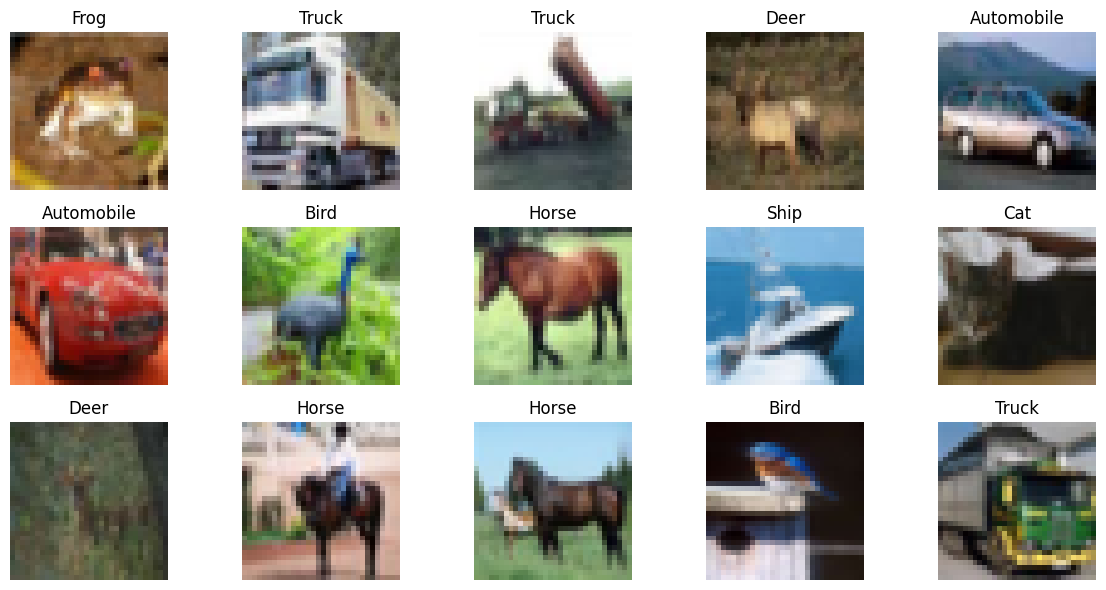

In [7]:
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train[i, 0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
#Block 4 — Normalize the images and prepare labels
# Convert pixel values from 0–255 to 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten labels from (N, 1) to (N,)
y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Training pixel range:",
      X_train.min(), "to", X_train.max())

print("Label shape:", y_train.shape)

Training shape: (50000, 32, 32, 3)
Testing shape: (10000, 32, 32, 3)
Training pixel range: 0.0 to 1.0
Label shape: (50000,)


In [9]:
#Block 5 — Create training and validation sets
#We'll reserve 5,000 images for validation, leaving 45,000 for training. The test set remains untouched until final evaluation.abs
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=5000,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (45000, 32, 32, 3) (45000,)
Validation: (5000, 32, 32, 3) (5000,)
Testing: (10000, 32, 32, 3) (10000,)


In [10]:
#Block 6 — Build the ResNet50 architecture
#ResNet50 uses bottleneck residual blocks. Each block applies three convolutions, while a shortcut path carries the input forward. When dimensions differ, a \(1\times1\) convolution projects the shortcut to the correct shape.
#This is a CIFAR-10 adaptation of ResNet50: it retains the 3-4-6-3 bottleneck stage configuration, but uses a smaller \(3\times3\) input convolution and omits the initial max-pooling layer to preserve spatial information in small images.
from tensorflow.keras import layers, Model

def bottleneck_block(
    x,
    filters,
    stride=1,
    projection=False,
    name=None
):
    """
    ResNet bottleneck block:
    1x1 conv -> 3x3 conv -> 1x1 conv
    plus a shortcut connection.
    """

    shortcut = x
    f1, f2, f3 = filters

    # First 1x1 convolution
    x = layers.Conv2D(
        f1, (1, 1),
        strides=stride,
        padding="same",
        use_bias=False,
        name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    # Second 3x3 convolution
    x = layers.Conv2D(
        f2, (3, 3),
        strides=1,
        padding="same",
        use_bias=False,
        name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    # Third 1x1 convolution
    x = layers.Conv2D(
        f3, (1, 1),
        strides=1,
        padding="same",
        use_bias=False,
        name=f"{name}_conv3"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn3")(x)

    # Projection shortcut when dimensions need to change
    if projection:
        shortcut = layers.Conv2D(
            f3, (1, 1),
            strides=stride,
            padding="same",
            use_bias=False,
            name=f"{name}_shortcut_conv"
        )(shortcut)

        shortcut = layers.BatchNormalization(
            name=f"{name}_shortcut_bn"
        )(shortcut)

    # Residual addition
    x = layers.Add(name=f"{name}_add")([x, shortcut])
    x = layers.Activation("relu", name=f"{name}_out")(x)

    return x

In [11]:
def build_resnet50(input_shape=(32, 32, 3), num_classes=10):

    inputs = layers.Input(shape=input_shape, name="input_image")

    # Initial convolution: adapted for CIFAR-10
    x = layers.Conv2D(
        64, (3, 3),
        strides=1,
        padding="same",
        use_bias=False,
        name="stem_conv"
    )(inputs)

    x = layers.BatchNormalization(name="stem_bn")(x)
    x = layers.Activation("relu", name="stem_relu")(x)

    # ResNet stage 2: 3 bottleneck blocks
    x = bottleneck_block(
        x, [64, 64, 256],
        projection=True,
        name="conv2_block1"
    )

    for i in range(2, 4):
        x = bottleneck_block(
            x, [64, 64, 256],
            name=f"conv2_block{i}"
        )

    # ResNet stage 3: 4 bottleneck blocks
    x = bottleneck_block(
        x, [128, 128, 512],
        stride=2,
        projection=True,
        name="conv3_block1"
    )

    for i in range(2, 5):
        x = bottleneck_block(
            x, [128, 128, 512],
            name=f"conv3_block{i}"
        )

    # ResNet stage 4: 6 bottleneck blocks
    x = bottleneck_block(
        x, [256, 256, 1024],
        stride=2,
        projection=True,
        name="conv4_block1"
    )

    for i in range(2, 7):
        x = bottleneck_block(
            x, [256, 256, 1024],
            name=f"conv4_block{i}"
        )

    # ResNet stage 5: 3 bottleneck blocks
    x = bottleneck_block(
        x, [512, 512, 2048],
        stride=2,
        projection=True,
        name="conv5_block1"
    )

    for i in range(2, 4):
        x = bottleneck_block(
            x, [512, 512, 2048],
            name=f"conv5_block{i}"
        )

    # Classification head
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="predictions"
    )(x)

    return Model(inputs, outputs, name="ResNet50_CIFAR10")


model = build_resnet50()

print("ResNet50 model created successfully!")

W0000 00:00:1790590885.288109   47679 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1790590885.302737   47679 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1790590885.317156   47679 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 10.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1790590885.437232   47679 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 173698 MB memory:  -> device: 0, name: NVIDIA B200, pci bus id: 0000:1b:00.0, compute capability: 10.0a
I0000 00:00:1790590885.452990   47679 gpu_device.cc:2043] Created devic

ResNet50 model created successfully!


In [12]:
model.summary()

Model: "ResNet50_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 32, 32,    │      1,728 │ input_image[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 32, 32,    │        256 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_relu           │ (None, 32, 32,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_conv1  │ (None, 32, 32,    │      4,096 │ stem_relu[0][0]   │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_bn1    │ (None, 32, 32,    │        256 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_relu1  │ (None, 32, 32,    │          0 │ conv2_block1_bn1… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_conv2  │ (None, 32, 32,    │     36,864 │ conv2_block1_rel… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_bn2    │ (None, 32, 32,    │        256 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_relu2  │ (None, 32, 32,    │          0 │ conv2_block1_bn2… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_conv3  │ (None, 32, 32,    │     16,384 │ conv2_block1_rel… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_short… │ (None, 32, 32,    │     16,384 │ stem_relu[0][0]   │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_bn3    │ (None, 32, 32,    │      1,024 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_short… │ (None, 32, 32,    │      1,024 │ conv2_block1_sho… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_add    │ (None, 32, 32,    │          0 │ conv2_block1_bn3… │
│ (Add)               │ 256)              │            │ conv2_block1_sho… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 32, 32,    │          0 │ conv2_block1_add… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_conv1  │ (None, 32, 32,    │     16,384 │ conv2_block1_out

 Total params: 23,573,962 (89.93 MB)

 Trainable params: 23,520,842 (89.72 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [13]:
%pip install pydot
tf.keras.utils.plot_model(
    model,
    to_file="resnet50_architecture.png",
    show_shapes=True,
    show_layer_names=False,
    expand_nested=True,
    dpi=80
)

Note: you may need to restart the kernel to use updated packages.
You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 compiled successfully!")

ResNet50 compiled successfully!


In [15]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

checkpoint = ModelCheckpoint(
    "best_resnet50_cifar10.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint, early_stop, reduce_lr]

In [16]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


I0000 00:00:1790590979.561359   48407 service.cc:153] XLA service 0x76a8140b8770 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1790590979.561384   48407 service.cc:161]   StreamExecutor [0]: NVIDIA B200, Compute Capability 10.0a (Driver: 12.9.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1790590979.561392   48407 service.cc:161]   StreamExecutor [1]: NVIDIA B200, Compute Capability 10.0a (Driver: 12.9.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1790590979.561394   48407 service.cc:161]   StreamExecutor [2]: NVIDIA B200, Compute Capability 10.0a (Driver: 12.9.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1790590979.868769   48407 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1790590982.040240   48407 cuda_dnn.cc:461] Loaded cuDNN version 91002
I0000 00:00:1790590982.249104   48407 dot_merger.cc:481] Merging

 10/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.1437 - loss: 4.5868

I0000 00:00:1790591003.123716   48407 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4568 - loss: 1.5766

I0000 00:00:1790591013.470510   48400 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_33241__.331


704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4570 - loss: 1.5761
Epoch 1: val_accuracy improved from None to 0.44300, saving model to best_resnet50_cifar10.keras

Epoch 1: finished saving model to best_resnet50_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 74s 46ms/step - accuracy: 0.4570 - loss: 1.5761 - val_accuracy: 0.4430 - val_loss: 1.8949 - learning_rate: 0.0010
Epoch 2/20
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6517 - loss: 0.9809
Epoch 2: val_accuracy improved from 0.44300 to 0.56720, saving model to best_resnet50_cifar10.keras

Epoch 2: finished saving model to best_resnet50_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6517 - loss: 0.9810 - val_accuracy: 0.5672 - val_loss: 1.5453 - learning_rate: 0.0010
Epoch 3/20
702/704 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7424 - loss: 0.7374
Epoch 3: val_accuracy did not improve from 0.56720
704/704 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.7424 - loss: 0.7374 - val_accuracy

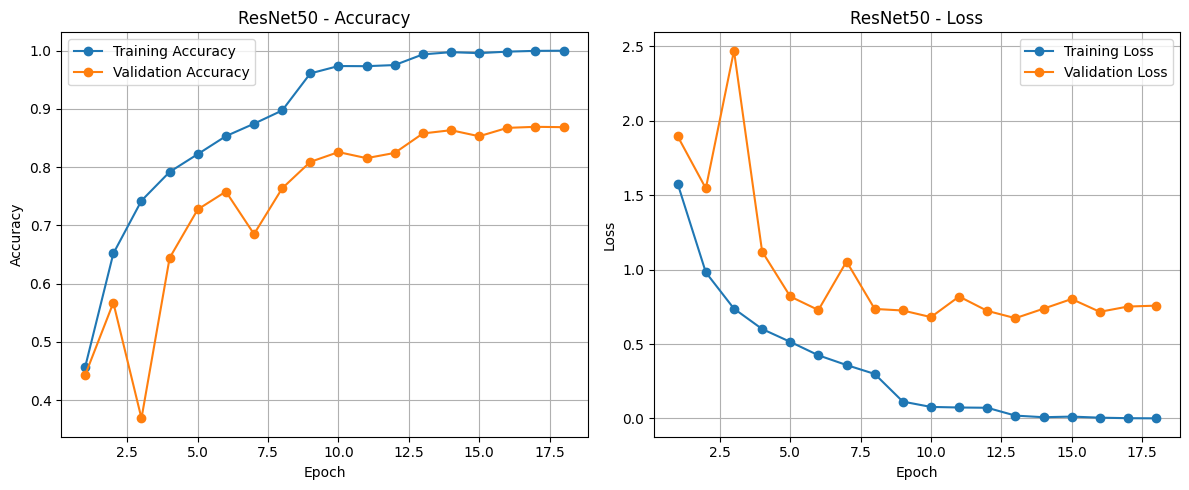

In [17]:
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, marker="o",
         label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, marker="o",
         label="Validation Accuracy")

plt.title("ResNet50 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, marker="o",
         label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o",
         label="Validation Loss")

plt.title("ResNet50 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [18]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=64,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.8512 - loss: 0.7481
Test Loss: 0.7481
Test Accuracy: 85.12%


In [19]:
y_pred_prob = model.predict(
    X_test,
    batch_size=64,
    verbose=1
)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step
Actual labels:    [3 8 8 0 6 6 1 6 3 1]
Predicted labels: [3 8 0 0 6 5 1 6 3 1]


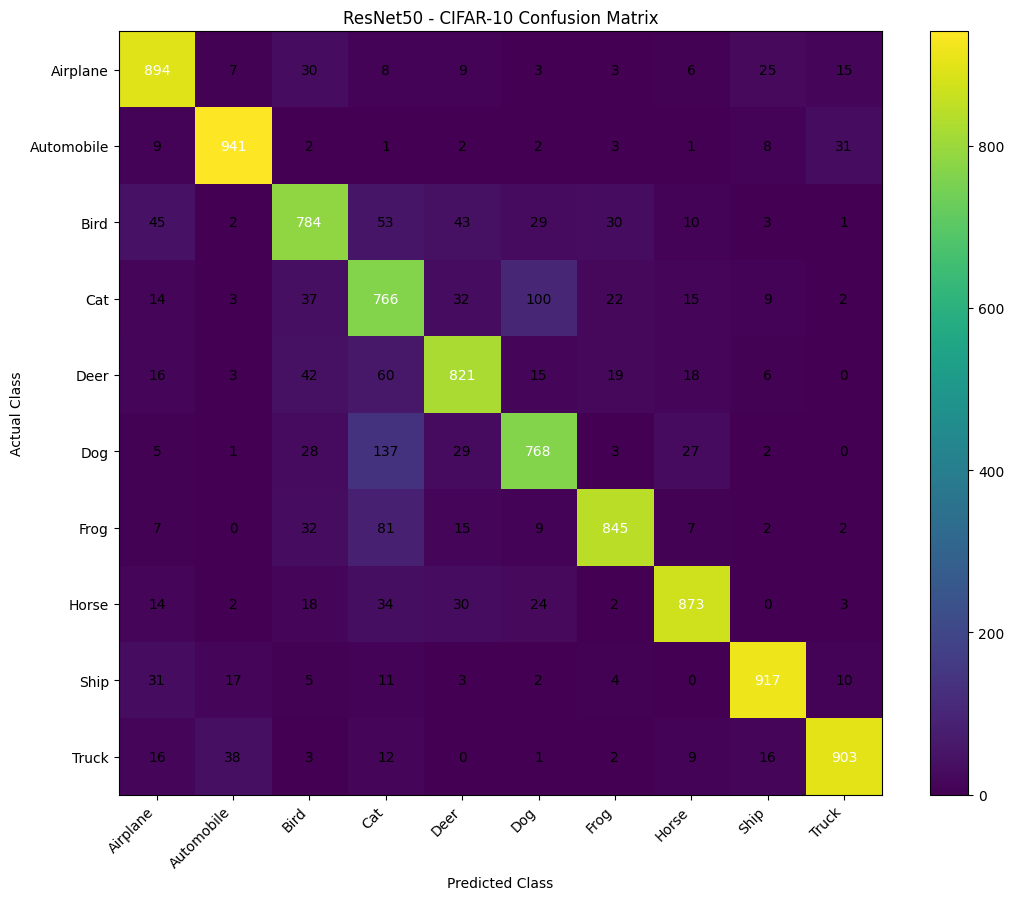

              precision    recall  f1-score   support

    Airplane     0.8506    0.8940    0.8718      1000
  Automobile     0.9280    0.9410    0.9345      1000
        Bird     0.7992    0.7840    0.7915      1000
         Cat     0.6586    0.7660    0.7083      1000
        Deer     0.8343    0.8210    0.8276      1000
         Dog     0.8059    0.7680    0.7865      1000
        Frog     0.9057    0.8450    0.8743      1000
       Horse     0.9037    0.8730    0.8881      1000
        Ship     0.9281    0.9170    0.9225      1000
       Truck     0.9338    0.9030    0.9181      1000

    accuracy                         0.8512     10000
   macro avg     0.8548    0.8512    0.8523     10000
weighted avg     0.8548    0.8512    0.8523     10000



In [21]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 9))

plt.imshow(cm, interpolation="nearest")
plt.title("ResNet50 - CIFAR-10 Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(class_names))

plt.xticks(tick_marks, class_names, rotation=45, ha="right")
plt.yticks(tick_marks, class_names)

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

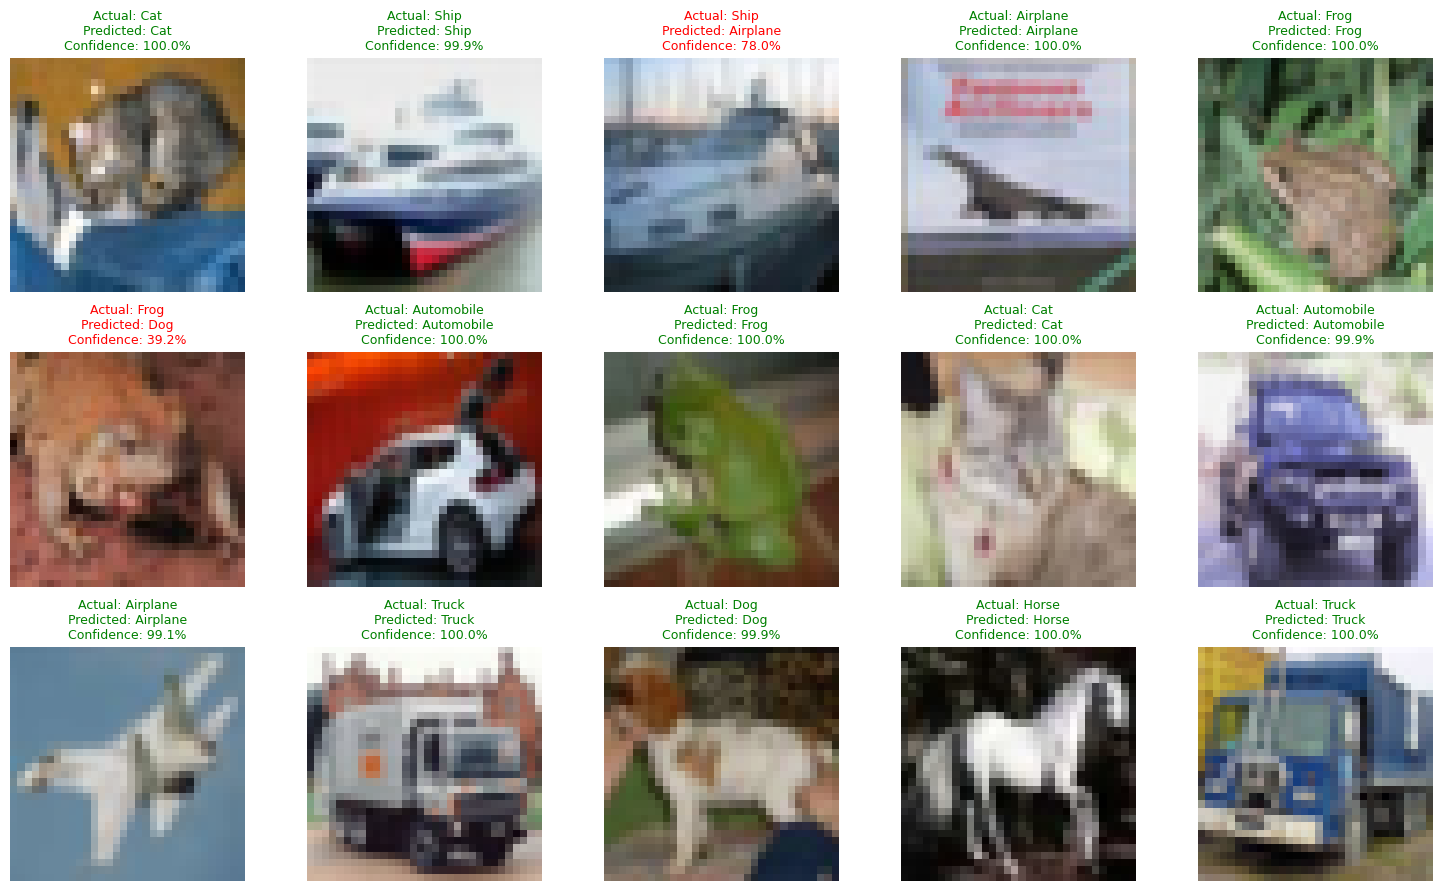

In [22]:
plt.figure(figsize=(15, 9))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i])

    actual_label = int(y_test[i])
    predicted_label = int(y_pred[i])
    confidence = np.max(y_pred_prob[i]) * 100

    color = (
        "green"
        if actual_label == predicted_label
        else "red"
    )

    plt.title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
model.save("resnet50_cifar10_final.keras")

print("Model saved successfully!")

Model saved successfully!
